# Упражнения по Boosting and Stacking 

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [48]:
from __future__ import print_function
import os
import warnings
data_path = [ 'data']
warnings.filterwarnings("ignore", category=FutureWarning) 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [49]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')

print('Размер данных: ', data.shape)

print(data.dtypes.value_counts())

Размер данных:  (10299, 562)
float64    561
str          1
Name: count, dtype: int64


В наборе данных довольно много столбцов с предикторами.

И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

In [50]:
target_col = data.select_dtypes(exclude='number').columns[0]
print('Целевой столбец:', target_col)
print(data[target_col].value_counts())

float_cols = data.select_dtypes(include='float').columns
print('Минимум по всем float-столбцам:', data[float_cols].min().min())
print('Максимум по всем float-столбцам:', data[float_cols].max().max())

Целевой столбец: Activity
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64
Минимум по всем float-столбцам: -1.0
Максимум по всем float-столбцам: 1.0


## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [51]:
SAMPLE_FRAC = 0.4

if SAMPLE_FRAC < 1.0:
    data = data.sample(frac=SAMPLE_FRAC, random_state=42).reset_index(drop=True)

le = LabelEncoder()
y = le.fit_transform(data[target_col])        
X = data.drop(columns=[target_col])          

for code_, name in enumerate(le.classes_):
    print(code_, '->', name)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('train:', X_train.shape, ' test:', X_test.shape)

0 -> LAYING
1 -> SITTING
2 -> STANDING
3 -> WALKING
4 -> WALKING_DOWNSTAIRS
5 -> WALKING_UPSTAIRS
train: (2884, 561)  test: (1236, 561)


## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

In [52]:
n_estimators_list = [25, 50, 100, 200, 400]
accuracies = []

for n in n_estimators_list:
    gbc = GradientBoostingClassifier(n_estimators=n, max_features=4, random_state=42)
    gbc.fit(X_train, y_train)
    acc = accuracy_score(y_test, gbc.predict(X_test))
    accuracies.append(acc)
    print(f'n_estimators={n:4d}  accuracy={acc:.4f}')

n_estimators=  25  accuracy=0.9159
n_estimators=  50  accuracy=0.9474
n_estimators= 100  accuracy=0.9636
n_estimators= 200  accuracy=0.9741
n_estimators= 400  accuracy=0.9782


Теперь построим график результата.

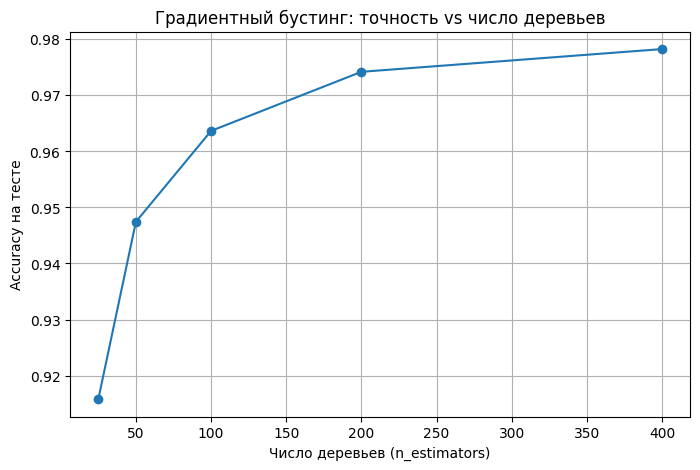

In [53]:

plt.figure(figsize=(8, 5))
plt.plot(n_estimators_list, accuracies, marker='o')
plt.xlabel('Число деревьев (n_estimators)')
plt.ylabel('Accuracy на тесте')
plt.title('Градиентный бустинг: точность vs число деревьев')
plt.grid(True)
plt.show()

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

In [54]:
param_grid = {
    'n_estimators': [100, 200, 400],
    'learning_rate': [0.1, 0.01],
    'subsample': [1.0, 0.5],
    'max_features': [2, 4],
}

gs_gbc = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid, scoring='accuracy', cv=3, n_jobs=-1)
gs_gbc.fit(X_train, y_train)

print('Лучшие параметры:', gs_gbc.best_params_)
print('Лучшая точность на кросс-валидации:', round(gs_gbc.best_score_, 4))


best_gbc = gs_gbc.best_estimator_
print(best_gbc)

Лучшие параметры: {'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 400, 'subsample': 0.5}
Лучшая точность на кросс-валидации: 0.9712
GradientBoostingClassifier(max_features=4, n_estimators=400, random_state=42,
                           subsample=0.5)


Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

In [55]:
y_pred_gbc = best_gbc.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_gbc), 4))
print(classification_report(y_test, y_pred_gbc, target_names=le.classes_))

Accuracy на тесте: 0.9782
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       253
           SITTING       0.97      0.94      0.96       217
          STANDING       0.94      0.97      0.95       214
           WALKING       1.00      0.99      0.99       209
WALKING_DOWNSTAIRS       0.98      0.99      0.98       166
  WALKING_UPSTAIRS       0.99      0.99      0.99       177

          accuracy                           0.98      1236
         macro avg       0.98      0.98      0.98      1236
      weighted avg       0.98      0.98      0.98      1236



Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

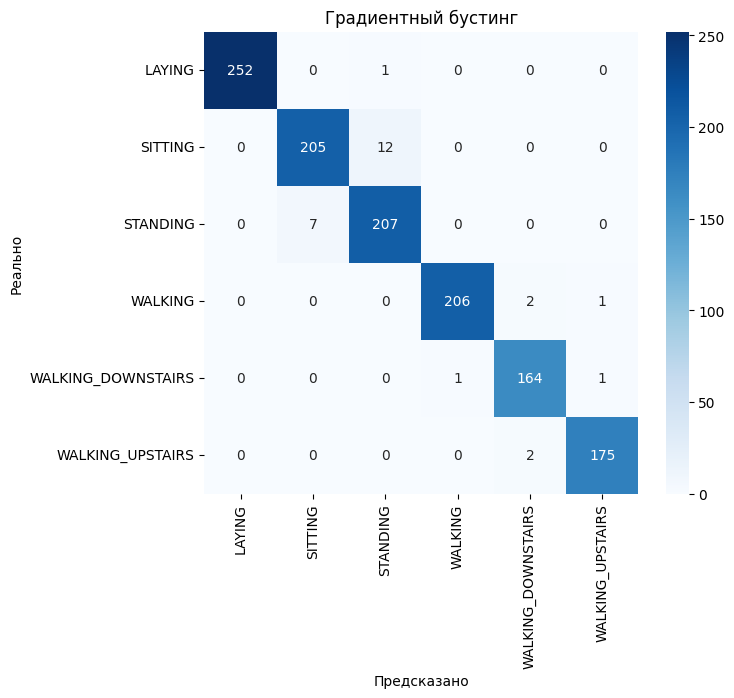

In [56]:
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.xlabel('Предсказано')
    plt.ylabel('Реально')
    plt.title(title)
    plt.show()

plot_cm(y_test, y_pred_gbc, 'Градиентный бустинг')

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

In [57]:
base_tree = DecisionTreeClassifier(max_depth=2, max_features=4, random_state=42)

param_grid_ada = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [1.0, 0.1, 0.01],
}

# Базовое дерево передаём первым аргументом (так работает во всех версиях sklearn)
gs_ada = GridSearchCV(AdaBoostClassifier(base_tree, random_state=42),
                      param_grid=param_grid_ada, scoring='accuracy', cv=3, n_jobs=-1)
gs_ada.fit(X_train, y_train)

print('Лучшие параметры AdaBoost:', gs_ada.best_params_)
print('Лучшая точность на кросс-валидации:', round(gs_ada.best_score_, 4))

Лучшие параметры AdaBoost: {'learning_rate': 0.1, 'n_estimators': 200}
Лучшая точность на кросс-валидации: 0.915


Лучшая модель.

Accuracy на тесте: 0.9167
                    precision    recall  f1-score   support

            LAYING       1.00      0.97      0.99       253
           SITTING       0.90      0.76      0.82       217
          STANDING       0.78      0.92      0.84       214
           WALKING       0.96      0.97      0.96       209
WALKING_DOWNSTAIRS       0.97      0.93      0.95       166
  WALKING_UPSTAIRS       0.92      0.95      0.94       177

          accuracy                           0.92      1236
         macro avg       0.92      0.92      0.92      1236
      weighted avg       0.92      0.92      0.92      1236



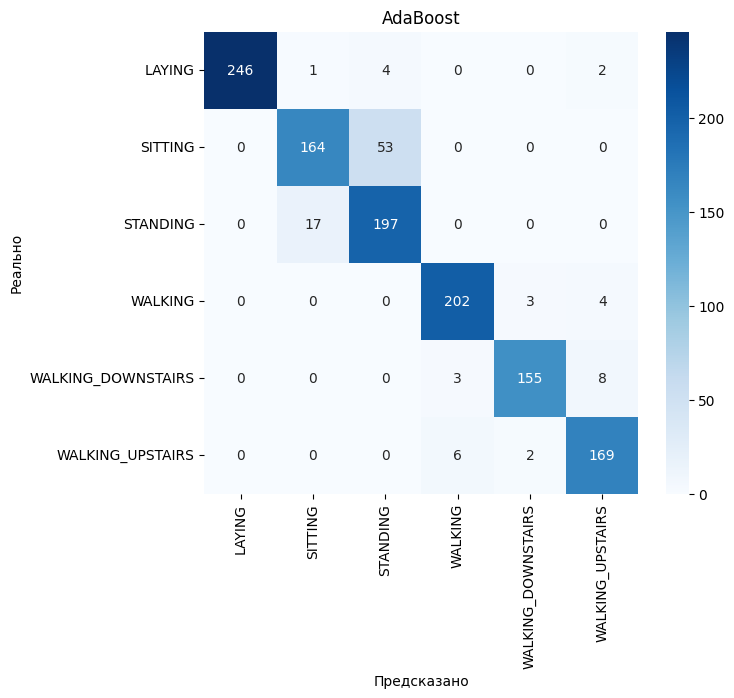

In [58]:
best_ada = gs_ada.best_estimator_
y_pred_ada = best_ada.predict(X_test)

print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_ada), 4))
print(classification_report(y_test, y_pred_ada, target_names=le.classes_))
plot_cm(y_test, y_pred_ada, 'AdaBoost')

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

In [59]:
compare = pd.DataFrame({
    'accuracy_test': [accuracy_score(y_test, y_pred_gbc), accuracy_score(y_test, y_pred_ada)]
}, index=['GradientBoosting', 'AdaBoost']).round(4)
compare

,accuracy_test
GradientBoosting,0.9782
AdaBoost,0.9167


## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

Accuracy на тесте: 0.9757
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       253
           SITTING       0.94      0.94      0.94       217
          STANDING       0.94      0.95      0.94       214
           WALKING       0.99      0.99      0.99       209
WALKING_DOWNSTAIRS       0.99      0.99      0.99       166
  WALKING_UPSTAIRS       0.99      0.99      0.99       177

          accuracy                           0.98      1236
         macro avg       0.98      0.98      0.98      1236
      weighted avg       0.98      0.98      0.98      1236



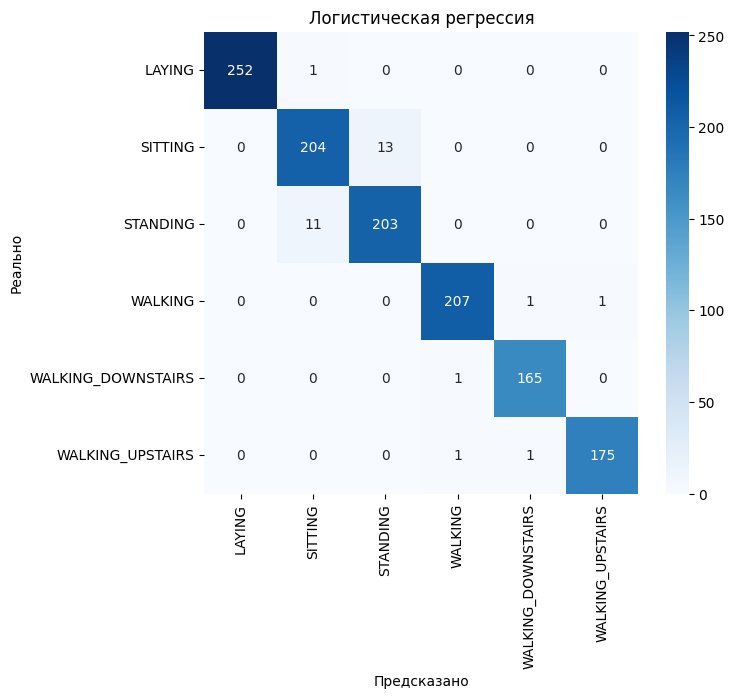

In [60]:
lr = LogisticRegressionCV(Cs=10, cv=3, max_iter=1000, n_jobs=-1)   
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_lr), 4))
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))
plot_cm(y_test, y_pred_lr, 'Логистическая регрессия')

А теперь — многоуровневая модель (stacked model).

In [61]:
vc = VotingClassifier(
    estimators=[('lr', LogisticRegressionCV(Cs=10, cv=3, max_iter=1000)),
                ('gbc', best_gbc),
                ('ada', best_ada)],
    voting='soft', n_jobs=-1)
vc.fit(X_train, y_train)

y_pred_vc = vc.predict(X_test)
print('Accuracy на тесте:', round(accuracy_score(y_test, y_pred_vc), 4))
print(classification_report(y_test, y_pred_vc, target_names=le.classes_))


results = pd.Series({
    'Логистическая регрессия': accuracy_score(y_test, y_pred_lr),
    'Градиентный бустинг':     accuracy_score(y_test, y_pred_gbc),
    'AdaBoost':                accuracy_score(y_test, y_pred_ada),
    'Voting (стекинг)':        accuracy_score(y_test, y_pred_vc),
}).round(4).sort_values(ascending=False)
results

Accuracy на тесте: 0.983
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       253
           SITTING       0.96      0.96      0.96       217
          STANDING       0.96      0.96      0.96       214
           WALKING       1.00      0.99      0.99       209
WALKING_DOWNSTAIRS       0.99      0.99      0.99       166
  WALKING_UPSTAIRS       0.99      0.99      0.99       177

          accuracy                           0.98      1236
         macro avg       0.98      0.98      0.98      1236
      weighted avg       0.98      0.98      0.98      1236



Voting (стекинг)           0.9830
Градиентный бустинг        0.9782
Логистическая регрессия    0.9757
AdaBoost                   0.9167
dtype: float64

Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

Лучшая модель: Voting (стекинг)


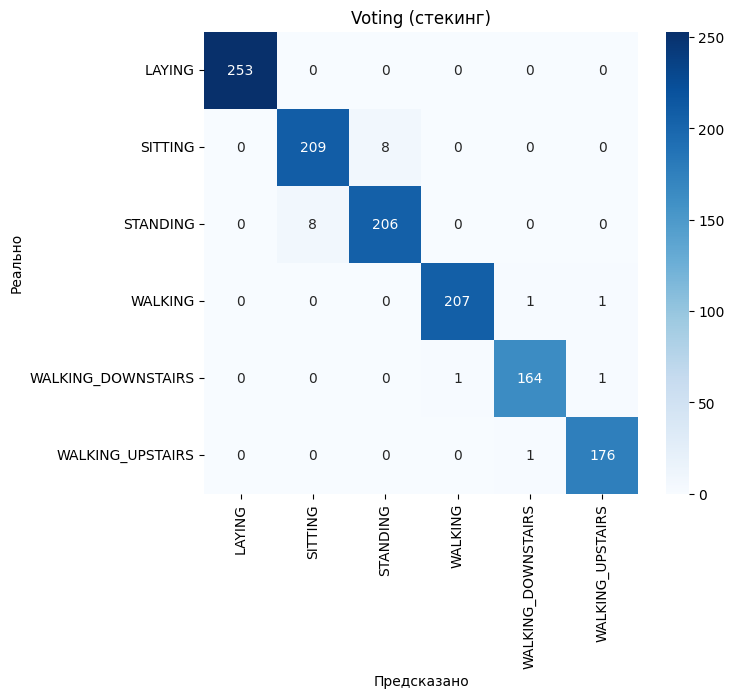

In [62]:
best_name = results.index[0]
preds = {'Логистическая регрессия': y_pred_lr, 'Градиентный бустинг': y_pred_gbc,
         'AdaBoost': y_pred_ada, 'Voting (стекинг)': y_pred_vc}

print('Лучшая модель:', best_name)
plot_cm(y_test, preds[best_name], best_name)